In [39]:
# Package Setup
import os
os.environ["OMP_NUM_THREADS"] = "2"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (accuracy_score, recall_score, precision_score, roc_auc_score,
                             silhouette_score, ConfusionMatrixDisplay, RocCurveDisplay)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [2]:
# Part 1 Setup
framingham = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\framingham.csv")

features = ["male", "age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
target = "TenYearCHD"

# KNN needs complete rows: drop patients missing any of these columns
fram = framingham.dropna(subset=features + [target]).reset_index(drop=True)
X = fram[features]
y = fram[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

def make_knn(k):
    return Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=k))])

print(f"{len(framingham)} patients, {len(fram)} with complete data")

4240 patients, 3802 with complete data


1.1 

- A model that predicts 0 true positives will have a recall of 0%. The ROC AUC for that same model will come out to 0.5 because of the lack of TP predictions. 

,k,accuracy,balanced_accuracy,roc_auc,roc_auc_sd,roc_auc_se
0,1,0.7715,0.5470,0.5470,0.0188,0.0084
1,5,0.8333,0.5404,0.6131,0.0271,0.0121
2,11,0.8451,0.5193,0.6422,0.0237,0.0106
3,25,0.8461,0.5014,0.6678,0.0260,0.0116
4,51,0.8468,0.5000,0.6811,0.0207,0.0092
5,75,0.8468,0.5000,0.6901,0.0244,0.0109
6,101,0.8468,0.5000,0.6966,0.0219,0.0098
7,151,0.8468,0.5000,0.7001,0.0196,0.0088
8,201,0.8468,0.5000,0.7053,0.0178,0.0080
9,251,0.8468,0.5000,0.7086,0.0240,0.0107


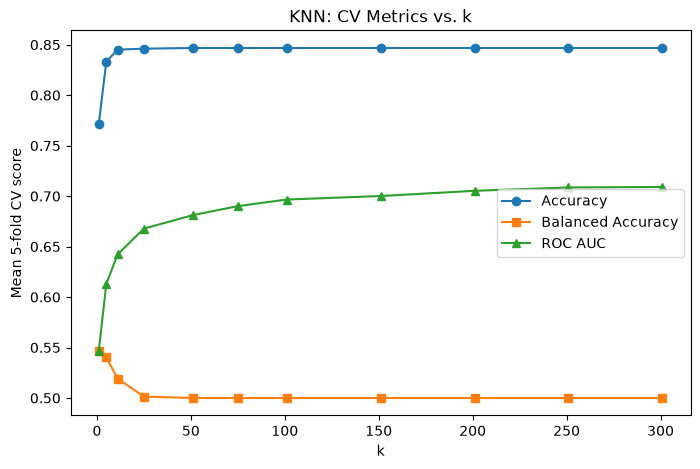

,k,roc_auc,roc_auc_se
7,151,0.700107,0.008781
8,201,0.705277,0.007968
9,251,0.708592,0.010726
10,301,0.709083,0.010928


In [44]:
# I used Gen AI to adapt to the notebook code. 
k_values = [1, 5, 11, 25, 51, 75, 101, 151, 201, 251, 301]
scoring = ["accuracy", "balanced_accuracy", "roc_auc"]

rows = []
for k in k_values:
    res = cross_validate(make_knn(k), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "k": k,
        "accuracy": res["test_accuracy"].mean(),
        "balanced_accuracy": res["test_balanced_accuracy"].mean(),
        "roc_auc": res["test_roc_auc"].mean(),
        "roc_auc_sd": res["test_roc_auc"].std(ddof=1),
        "roc_auc_se": res["test_roc_auc"].std(ddof=1) / np.sqrt(5),
    })

knn_results = pd.DataFrame(rows)
display(knn_results.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(knn_results["k"], knn_results["accuracy"], marker="o", label="Accuracy")
ax.plot(knn_results["k"], knn_results["balanced_accuracy"], marker="s", label="Balanced Accuracy")
ax.plot(knn_results["k"], knn_results["roc_auc"], marker="^", label="ROC AUC")
ax.set(xlabel="k", ylabel="Mean 5-fold CV score", title="KNN: CV Metrics vs. k")
ax.legend()
plt.show()

best_idx = knn_results["roc_auc"].idxmax()
best_auc = knn_results.loc[best_idx, "roc_auc"]
best_se = knn_results.loc[best_idx, "roc_auc_se"]
cutoff = best_auc - best_se
display(knn_results[knn_results["roc_auc"] >= cutoff][["k", "roc_auc", "roc_auc_se"]])

1.2 

- The K with the highest CV accuracy is 51 and all Ks after that have the exact same CV accuracy. The predicted CHD values of 51, 0, and 0 for K = 11, 51, and 151 respectively are directed connected to the increasing accuracy. As the neighborhoods increase in size, noise is averaged out and the accuracy eventually converges.  

- As the number of positive CHD predictions decrease through each K, the number of recalls also decreases. 

- The K with the highest CV ROC AUC is k=301 with an AUC of 0.7091. Within one standard error, the farthest ROC AUC value is 0.7001 at K = 151. 

In [48]:
probs = cross_val_predict(make_knn(k), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print(probs.max())

0.3289036544850498


--- Threshold 0.5 ---
Accuracy:  0.8468
Recall:    0.0000
Precision: 0.0000
--- Threshold 0.2 ---
Accuracy:  0.8145
Recall:    0.2876
Precision: 0.3661


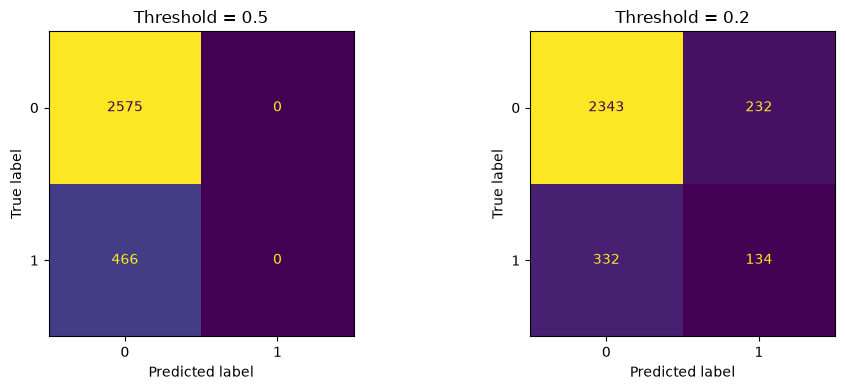

In [ ]:
pred = cross_val_predict(make_knn(k), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
a5 = (pred >= 0.5).astype(int)
a2 = (pred >= 0.2).astype(int)

# I use Gen AI to assist with the plot and reporting metrics. 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, thresh, preds in zip(axes, [0.5, 0.2], [a5, a2]):
    ConfusionMatrixDisplay.from_predictions(y_train, preds, ax=ax, colorbar=False)
    ax.set_title(f"Threshold = {thresh}")
    print(f"--- Threshold {thresh} ---")
    print(f"Accuracy:  {accuracy_score(y_train, preds):.4f}")
    print(f"Recall:    {recall_score(y_train, preds, zero_division=0):.4f}")
    print(f"Precision: {precision_score(y_train, preds, zero_division=0):.4f}")

plt.tight_layout()
plt.show()

1.3 

- predict() never predicts a positive CHD case because each neighborhood maintains a proportion of positive cases well below 0.5, resulting in every prediction being negative. 

- 0.2 would be the better threshold for cautious purposes. Choosing K by the ROC AUC is better than the accuracy because accuracy is heavily impacted by class imbalance. It makes sense to choose the threshold separately since we can keep the rankings separated from the prediction. 

0.7704982215851781
0.8107752956636005
0.39316239316239315
0.3865546218487395


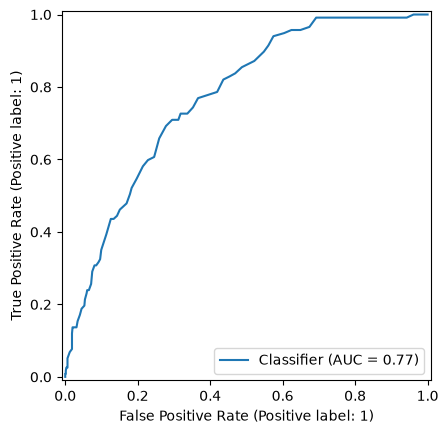

In [54]:
knn_final = make_knn(k)
knn_final.fit(X_train, y_train)

test_probs = knn_final.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.2).astype(int)

print(roc_auc_score(y_test, test_probs))
print(accuracy_score(y_test, test_preds))
print(recall_score(y_test, test_preds))
print(precision_score(y_test, test_preds))

RocCurveDisplay.from_predictions(y_test, test_probs)
plt.show()

1.4 

- The test ROC AUC is 0.7705. At a threshold of 0.2, the test accuracy is 0.8108, the test recall is 0.3932, and the test precision is 0.3866. 

- The CV and test ROC AUC values come out very similar, indicating that no change in conclusion is necessary. As for picking a different k, we should not do this because the test set has already been evaluated. 

In [3]:
# Part 2-3 Setup
auto = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\Auto.csv", na_values="?").dropna().reset_index(drop=True)

auto_feats = ["mpg", "displacement", "horsepower", "weight", "acceleration"]
Xa = auto[auto_feats]

scaler = StandardScaler()
Xa_s = scaler.fit_transform(Xa)   # 392 cars x 5 standardized features (a NumPy array)
print(auto.shape)

(392, 9)


In [4]:
summary = Xa.agg(["mean", "std", "min", "max"]).T
summary.columns = ["Mean", "SD", "Min", "Max"]
summary

,Mean,SD,Min,Max
mpg,23.445918,7.805007,9.0,46.6
displacement,194.411990,104.644004,68.0,455.0
horsepower,104.469388,38.491160,46.0,230.0
weight,2977.584184,849.402560,1613.0,5140.0
acceleration,15.541327,2.758864,8.0,24.8


    min   max  count
0  3693  5140     90
1  1613  2694    180
2  2700  3672    122


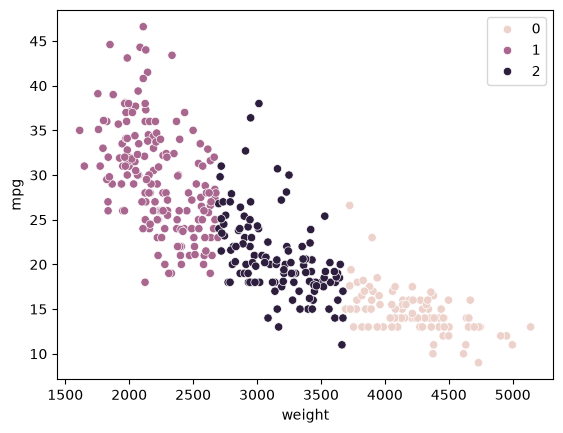

In [5]:
kmeans = KMeans(n_clusters=3, n_init=20, random_state=0)
kmeans.fit(Xa)

print(Xa.groupby(kmeans.labels_)["weight"].agg(["min", "max", "count"]))

sns.scatterplot(data=Xa, x="weight", y="mpg", hue=kmeans.labels_)
plt.show()

2.1 

- Kmeans made its clusters based on the weight. It did this because the unscaled data shows the largest differences in the weight over the other features, so the clusters made centroids based on this because of the Euclidean distances heavily factoring the weight. 

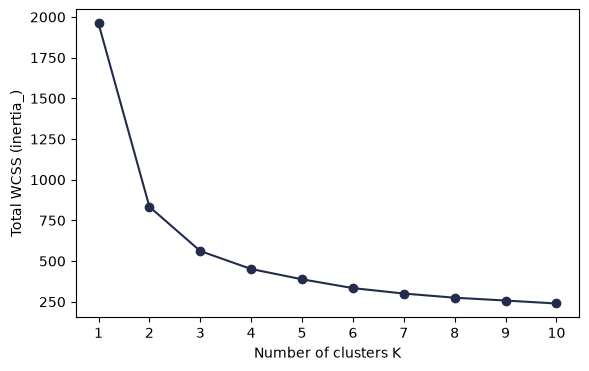

In [ ]:
Ks = range(1, 11)
rows = []
for k in Ks:
    m = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Xa_s)
    rows.append({"K": k, "WCSS": m.inertia_,
                 "avg silhouette": silhouette_score(Xa_s, m.labels_) if k > 1 else np.nan})

choose_k = pd.DataFrame(rows).set_index("K")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(choose_k.index, choose_k["WCSS"], marker="o", color="#232D4B")
ax.set_xlabel("Number of clusters K")
ax.set_ylabel("Total WCSS (inertia_)")
ax.set_xticks(list(Ks))
plt.show()

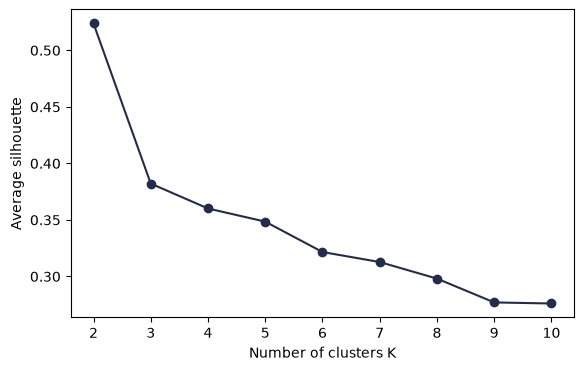

Largest average silhouette: K = 2 (0.524)


In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(choose_k.index[1:], choose_k["avg silhouette"].iloc[1:], marker="o", color="#232D4B")
ax.set_xlabel("Number of clusters K")
ax.set_ylabel("Average silhouette")
ax.set_xticks(list(Ks)[1:])
plt.show()

best_k = choose_k["avg silhouette"].idxmax()
print(f"Largest average silhouette: K = {best_k} ({choose_k.loc[best_k, 'avg silhouette']:.3f})")

2.2 

- The elbow in the WCSS plot is at K=2. 

- The K with the largest average silhouette is K=2. 

- If I had to choose a K value, I'd pick K=2 because it's the WCSS elbow and has the largest average silhouette. 

In [20]:
kmeans = KMeans(n_clusters=3, n_init=20, random_state=0)
km3 = kmeans.fit(Xa_s)

df = auto.copy()
df["kmeans3"] = km3.labels_

profile = df.groupby("kmeans3")[auto_feats].mean().round(1)
profile.insert(0, "n", df["kmeans3"].value_counts().sort_index())
display(profile)

print(pd.crosstab(df["kmeans3"], df["cylinders"]))
print(pd.crosstab(df["kmeans3"], df["origin"]))
print(df.groupby("kmeans3")["year"].mean().round(1))

,n,mpg,displacement,horsepower,weight,acceleration
kmeans3,,,,,,
0,147,31.6,103.2,72.9,2189.8,16.8
1,148,21.2,184.3,98.3,2995.6,16.2
2,97,14.5,348.0,161.8,4144.0,12.6


cylinders  3    4  5   6   8
kmeans3                     
0          0  144  1   2   0
1          4   55  2  80   7
2          0    0  0   1  96
origin     1   2   3
kmeans3             
0         44  45  58
1        104  23  21
2         97   0   0
kmeans3
0    77.6
1    75.9
2    73.6
Name: year, dtype: float64


2.3 

- The 3rd cluster is entirely American. The four-cylinder cars all end up in the 1st and 2nd clusters. Among the variables we left out, the clusters line up with the cylinder counts very well. Each cluster has a very significant majority of one certain cylinder count. 

In [21]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=0)
km2 = kmeans.fit(Xa_s)

df["kmeans2"] = km2.labels_

print(pd.crosstab(df["kmeans2"], df["kmeans3"]))
print(pd.crosstab(df["kmeans2"], df["cylinders"]))

kmeans3    0    1   2
kmeans2              
0          0    4  97
1        147  144   0
cylinders  3    4  5   6   8
kmeans2                     
0          0    0  0   2  99
1          4  199  3  81   4


2.4 

- The K=2 clusters almost completely separate the first two clusters in K=3 from the third cluster. The K=2 clusters also almost completely separate the cars with 8 cylinders from the rest of the cars. 

- The clusters are almost nested, but they're not! K-means does not have to give nested solutions because for each K, a brand new problem is solved to identify centroids and clusters.m 

In [ ]:
rows = []
for method in ["single", "complete", "average", "ward"]:
    labs = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(Xa_s)
    rows.append({"linkage": method, "cluster sizes": sorted(np.bincount(labs), reverse=True),
                 "avg silhouette": round(silhouette_score(Xa_s, labs), 3)})

rows.append({"linkage": "kmeans", "cluster sizes": sorted(np.bincount(km3.labels_), reverse=True),
             "avg silhouette": round(silhouette_score(Xa_s, km3.labels_), 3)})

pd.DataFrame(rows)
rows

,linkage,cluster sizes,avg silhouette
0,single,"[390, 1, 1]",-0.059
1,complete,"[200, 97, 95]",0.343
2,average,"[291, 97, 4]",0.422
3,ward,"[212, 99, 81]",0.374
4,kmeans,"[148, 147, 97]",0.382


3.1

- Single and average linkage give very lopsided clusters, singling out individual cars. 

- The two cars are a Buick Estate Wagon and an Oldsmobile Cutlass Ciera, which are not typical vehicles found on the road today due to their age and outdated builds. These cars were likely given their own clusters due to their large displacements from the rest of the sample. 

- Average linkage actually gives the highest average silhouette. However, this does not make the best clusters. Average linkage has the highest average silhouette because it separated potential outliers from the rest of the sample. 

[ 6.33  7.27  8.56 10.08 11.64 14.5  22.43 47.39]
K=2: 0.5249638078700021
K=3: 0.37351249903405453
K=4: 0.31282258889543135
K=5: 0.32737273751347234
K=6: 0.29063308713112007
K=7: 0.29546643239577774
K=8: 0.26327410589021627


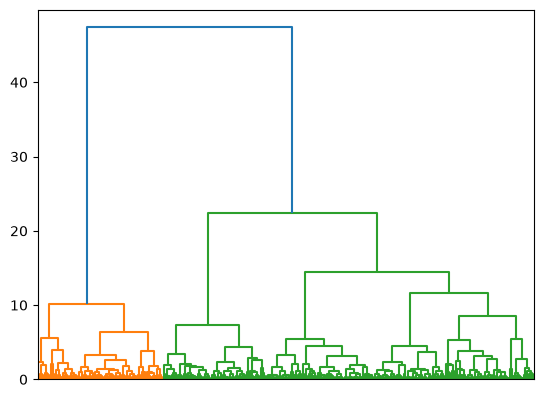

In [41]:
Z = linkage(Xa_s, method="ward")
dendrogram(Z, no_labels=True)
print(np.round(Z[-8:, 2], 2))
for K in range(2, 9):
    print(f"K={K}: {silhouette_score(Xa_s, fcluster(Z, t=K, criterion="maxclust"))}")

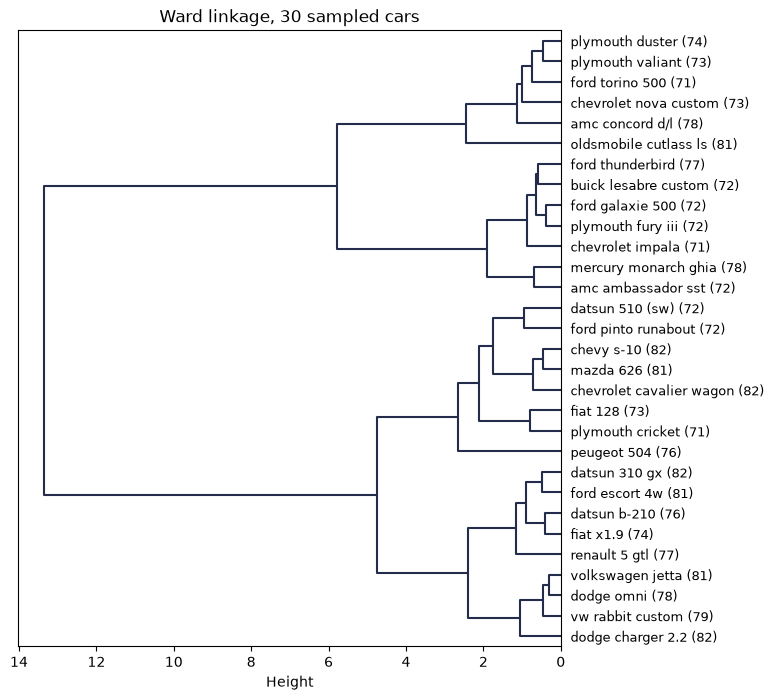

In [7]:
# Q2b: 30 cars sampled at random, labeled by name and model year.
rng = np.random.default_rng(6021)
samp = np.sort(rng.choice(len(auto), 30, replace=False))
names = (auto.loc[samp, "name"] + " (" + auto.loc[samp, "year"].astype(str) + ")").to_list()

fig, ax = plt.subplots(figsize=(7, 8))
dendrogram(linkage(Xa_s[samp], method="ward"), labels=names, orientation="left",
           color_threshold=0, above_threshold_color="#232D4B", leaf_font_size=9, ax=ax)
ax.set(xlabel="Height", title="Ward linkage, 30 sampled cars")
plt.show()

3.2 

- The biggest jump would then be 24.97 followed by 7.93 with the cluster amounts respectively being K=2 and K=3. My silhouette results do agree with the Kmeans results from the last question. 

- The two cars that would merge first would be the Volkswagen Jetta and Dodge Omni. If I had to divide the dendogram into three clusters, I'd make the first cluster the entire top half, the second cluster the next fourth, and the third cluster the remaining fourth. These clusters would be made based on the size, cylinder count, and overall build of the vehicle. 

In [36]:
# I used VScode autofill to assist with this. 
df["kmeans2"] = KMeans(n_clusters=2, n_init=20, random_state=0).fit_predict(Xa_s)
df["kmeans3"] = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(Xa_s)

Z = linkage(Xa_s, method="ward")
df["ward2"] = fcluster(Z, t=2, criterion="maxclust")
df["ward3"] = fcluster(Z, t=3, criterion="maxclust")

ct2 = pd.crosstab(df["ward2"], df["kmeans2"], rownames=["Ward (K=2)"], colnames=["K-means (K=2)"])
display(ct2)

ct3 = pd.crosstab(df["ward3"], df["kmeans3"], rownames=["Ward (K=3)"], colnames=["K-means (K=3)"])
display(ct3)

K-means (K=2),0,1
Ward (K=2),,
1,99,0
2,2,291


K-means (K=3),0,1,2
Ward (K=3),,,
1,0,2,97
2,0,81,0
3,147,65,0


In [34]:
pd.crosstab(df["ward3"], df["cylinders"])

cylinders,3,4,5,6,8
ward3,,,,,
1,0,0,0,2,97
2,0,4,1,70,6
3,4,195,2,11,0


In [42]:
# I used Gen AI to assist with WCSS calculation.
ward3 = df["ward3"].to_numpy()
ward_wcss = sum(((Xa_s[ward3 == k] - Xa_s[ward3 == k].mean(axis=0)) ** 2).sum()
                for k in np.unique(ward3))

km3 = KMeans(n_clusters=3, n_init=20, random_state=0).fit(Xa_s)
print(ward_wcss)
print(km3.inertia_)

585.3556962928101
561.670773076191


3.3 

- Amongst the K=2 clusters, there's agreement in 390 cars. Amongst the K=3 clusters, there's agreement in 325 cars. 

- The 3rd cluster lines up well with cars that have four cylinders, the 2nd cluster lines up decently with cars that have 6 cylinders, and the first cluster lines up well with cars that have 8 cylinders. 

- The Ward WCSS comes out as 585.4 and the K-means WCSS comes out at 561.7. Even though both methods have the same goal, K-means accomplished its goal better by simply assigning clusters based on centroids, where Ward may have been greedy trying to minimize the WCSS step by step and unintentionally harming the clusters. 

3.4 

- One advantage of hierarchical clustering over K-means is the ability to organize and select your own clusters and one disadvantage is the poor performance selecting clusters for larger datasets. For a dataset with 100,000 cars, I'd use K-means clustering so the clusters could be sorted for me.

In [55]:
# Part 4 Setup
from scipy.spatial.distance import squareform
from kmodes.kprototypes import KPrototypes

ins = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\insurance.csv")
ins_num = ["age", "bmi", "children"]
ins_cat = ["sex", "smoker", "region"]

def gower_matrix(data, numeric, categorical, weights=None):
    # Gower distance, as in hierarchical_clustering.ipynb, with optional weights:
    # a dict {column: weight}. Columns not in the dict get a weight of 1.
    weights = weights or {}
    n = len(data)
    D = np.zeros((n, n))
    total_weight = 0
    for col in numeric:
        w = weights.get(col, 1)
        x = data[col].to_numpy(dtype=float)
        D += w * np.abs(x[:, None] - x[None, :]) / (x.max() - x.min())   # 0-1 by the range
        total_weight += w
    for col in categorical:
        w = weights.get(col, 1)
        x = data[col].to_numpy()
        D += w * (x[:, None] != x[None, :])                               # 0 = match, 1 = differ
        total_weight += w
    return D / total_weight

def gower_clusters(D, method, K=3):
    # Hierarchical clustering on a precomputed distance matrix, cut into K clusters
    return fcluster(linkage(squareform(D, checks=False), method=method), t=K, criterion="maxclust")

# For K-prototypes: standardized numeric columns first, then the categorical columns as they are
X_mixed = ins[ins_num + ins_cat].copy()
X_mixed[ins_num] = StandardScaler().fit_transform(ins[ins_num])
cat_idx = [3, 4, 5]     # positions of the categorical columns in X_mixed

In [60]:
G = gower_matrix(ins, ins_num, ins_cat)
print(G[0,1])

# I used Gen AI to assist with calculating the feature averages. 
for col in ins_num:
    x = ins[col].to_numpy(dtype=float)
    D_col = np.abs(x[:, None] - x[None, :]) / (x.max() - x.min())
    print(f"{col:10s}: {squareform(D_col).mean():.4f}")

for col in ins_cat:
    x = ins[col].to_numpy()
    D_col = (x[:, None] != x[None, :]).astype(float)
    print(f"{col:10s}: {squareform(D_col).mean():.4f}")

0.5632770311104873
age       : 0.3524
bmi       : 0.1855
children  : 0.2551
sex       : 0.5003
smoker    : 0.3259
region    : 0.7499


4.1 

- (0.0217 + 1 + 0.1579 + 1 + 1 + 0.2)/6 = 0.5633

- The categorical averages(0.5003, 0.3259, and 0.7499) are larger than the numeric averages(0.3524, 0.1855, and 0.2551). 

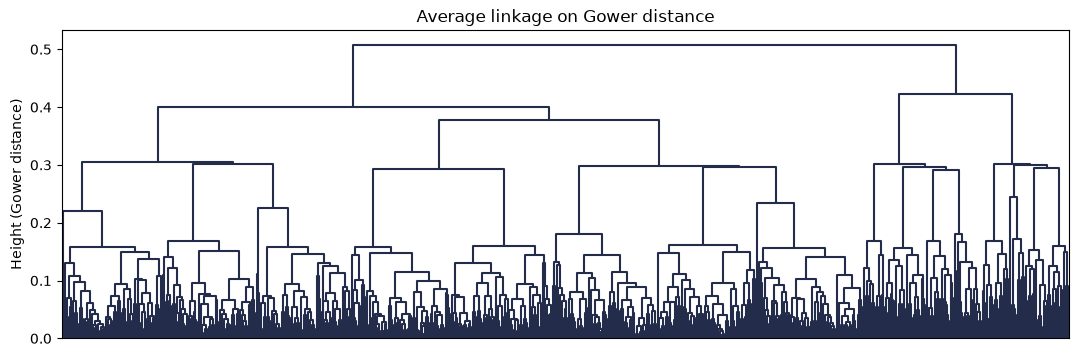


Average linkage


,n,age,bmi,children
avg3,,,,
1,1064,39.4,30.7,1.1
2,159,38.4,31.5,1.2
3,115,38.6,29.6,1.0


sex      smoker         region                              
     female male     no  yes northeast northwest southeast southwest
avg3                                                                
1       547  517   1064    0       257       267       273       267
2         0  159      0  159        38        29        55        37
3       115    0      0  115        29        29        36        21


Complete linkage


,n,age,bmi,children
comp3,,,,
1,274,38.5,30.7,1.1
2,517,39.1,30.8,1.1
3,547,39.7,30.5,1.1


sex      smoker         region                              
      female male     no  yes northeast northwest southeast southwest
comp3                                                                
1        115  159      0  274        67        58        91        58
2          0  517    517    0       125       132       134       126
3        547    0    547    0       132       135       139       141

In [ ]:
ins["avg3"]  = gower_clusters(G, "average")
ins["comp3"] = gower_clusters(G, "complete")

# I had Gen AI create the dendogram and the crosstabs. 
Z_avg = linkage(squareform(G, checks=False), method="average")
fig, ax = plt.subplots(figsize=(13, 4))
dendrogram(Z_avg, no_labels=True, color_threshold=0, above_threshold_color="#232D4B", ax=ax)
ax.set(ylabel="Height (Gower distance)", title="Average linkage on Gower distance")
plt.show()

for col, name in [("avg3", "Average linkage"), ("comp3", "Complete linkage")]:
    print(f"\n{name}")
    profile = ins.groupby(col)[ins_num].mean().round(1)
    profile.insert(0, "n", ins[col].value_counts().sort_index())
    display(profile)
    display(pd.concat([pd.crosstab(ins[col], ins[c]) for c in ins_cat], axis=1, keys=ins_cat))

In [ ]:
G_nosex = gower_matrix(ins, ins_num, ["smoker", "region"])
G_half = gower_matrix(ins, ins_num, ins_cat, weights={"sex": 0.5, "smoker": 0.5, "region": 0.5})

ins["nosex3"] = gower_clusters(G_nosex, "average")
ins["half3"]  = gower_clusters(G_half, "average")

for col, name in [("nosex3", "Fix (i): no sex"), ("half3", "Fix (ii): categorical weight 0.5")]:
    print(f"\n{name}")
    profile = ins.groupby(col)[ins_num].mean().round(1)
    profile.insert(0, "n", ins[col].value_counts().sort_index())
    display(profile)
    display(pd.concat([pd.crosstab(ins[col], ins[c]) for c in ins_cat], axis=1, keys=ins_cat))


Fix (i): no sex


,n,age,bmi,children
nosex3,,,,
1,365,38.9,33.3,1.1
2,324,39.3,29.2,1.0
3,649,39.3,29.9,1.1


sex      smoker         region                              
       female male     no  yes northeast northwest southeast southwest
nosex3                                                                
1         176  189    274   91         0         1       364         0
2         161  163    257   67       324         0         0         0
3         325  324    533  116         0       324         0       325


Fix (ii): categorical weight 0.5


,n,age,bmi,children
half3,,,,
1,10,33.1,28.4,5.0
2,268,38.1,30.8,1.1
3,1060,39.5,30.6,1.1


sex      smoker         region                              
      female male     no  yes northeast northwest southeast southwest
half3                                                                
1          3    7      9    1         0         0         3         7
2        109  159      0  268        67        53        91        57
3        550  510   1055    5       257       272       270       261

4.2 

- The variables that decided the clusters are the categorical variables. 

- The clusters are dominated by the categorical variables because every class difference adds large categorical differences to the total Gower distance. 

- When we drop sex, dendogram plot no longer splits for the binary variable, giving more room for the other variables to have an impact. When we bring the weight of the categorical variables down to 0.5, this allows the numeric variables to have a much more even share of the impact on the clustering. 

In [68]:
KP = KPrototypes(n_clusters=3, init="Huang", n_init=10, random_state=0)
KP.fit(X_mixed, categorical=cat_idx)

print(KP.gamma)

ins["kp_default"] = KP.labels_

# VScode autofill sped this up for me. 
profile_kp = ins.groupby("kp_default")[ins_num].mean().round(1)
profile_kp.insert(0, "n", ins["kp_default"].value_counts().sort_index())
display(profile_kp)
display(pd.concat([pd.crosstab(ins["kp_default"], ins[c]) for c in ins_cat], axis=1, keys=ins_cat))

0.5


,n,age,bmi,children
kp_default,,,,
0,460,52.8,31.6,0.5
1,387,40.2,30.9,2.7
2,491,25.7,29.6,0.4


sex      smoker         region                              
           female male     no  yes northeast northwest southeast southwest
kp_default                                                                
0             253  207    378   82       127        98       118       117
1             177  210    301   86        82       112        96        97
2             232  259    385  106       115       115       150       111

In [69]:
KP_10 = KPrototypes(n_clusters=3, init="Huang", n_init=10, gamma=10, random_state=0)
KP_10.fit(X_mixed, categorical=cat_idx)

ins["kp_10"] = KP_10.labels_

profile_kp10 = ins.groupby("kp_10")[ins_num].mean().round(1)
profile_kp10.insert(0, "n", ins["kp_10"].value_counts().sort_index())
display(profile_kp10)
display(pd.concat([pd.crosstab(ins["kp_10"], ins[c]) for c in ins_cat], axis=1, keys=ins_cat))

,n,age,bmi,children
kp_10,,,,
0,625,40.0,30.6,0.9
1,439,38.6,28.7,1.5
2,274,38.3,34.0,0.9


sex      smoker         region                              
      female male     no  yes northeast northwest southeast southwest
kp_10                                                                
0        545   80    568   57       152        92       139       242
1         69  370    408   31       125       222        46        46
2         48  226     88  186        47        11       179        37

In [71]:
# I used Gen AI to compute the average squared distances. 
num_centers = KP.cluster_centroids_[:, :3].astype(float)

X_num = X_mixed[ins_num].to_numpy()
sq_dist = ((X_num - num_centers[KP.labels_]) ** 2).sum(axis=1)

print(sq_dist.mean())

1.6228314609908057


4.3 

- The default gamma value was 0.5. Unlike the clusters from Q2, these clusters are heavily decided by the numerical variables here. Among categorical variables, the sex, smoker, and regional combinagions are split pretty evenly. 

- When we refit with gamma=10, the clusters return to being decided by the categorical variables. 

- The average squared distance is 1.623, which is over three times larger than the default gamma value 0.5. A mismatch with the default gamma value adds 0.5 do the distance. The Gower and KP clusters are so different because Gower gives a full point to the difference per categorical mismatch while KP uses squared Euclidean distances for its numeric variables. 


Gower, average linkage


,n,mean_charges,median_charges,smokers
avg3,,,,
1,1064,8434.0,7345.0,0
2,159,33042.0,36085.0,159
3,115,30679.0,28950.0,115



Gower, categorical weight 0.5


,n,mean_charges,median_charges,smokers
half3,,,,
1,10,8692.0,6660.0,1
2,268,32112.0,34645.0,268
3,1060,8550.0,7395.0,5



K-prototypes, default γ


,n,mean_charges,median_charges,smokers
kp_default,,,,
0,460,16171.0,11753.0,82
1,387,14578.0,9302.0,86
2,491,9522.0,3867.0,106



K-prototypes, γ = 10


,n,mean_charges,median_charges,smokers
kp_10,,,,
0,625,10284.0,8520.0,57
1,439,9734.0,7527.0,31
2,274,25748.0,24424.0,186


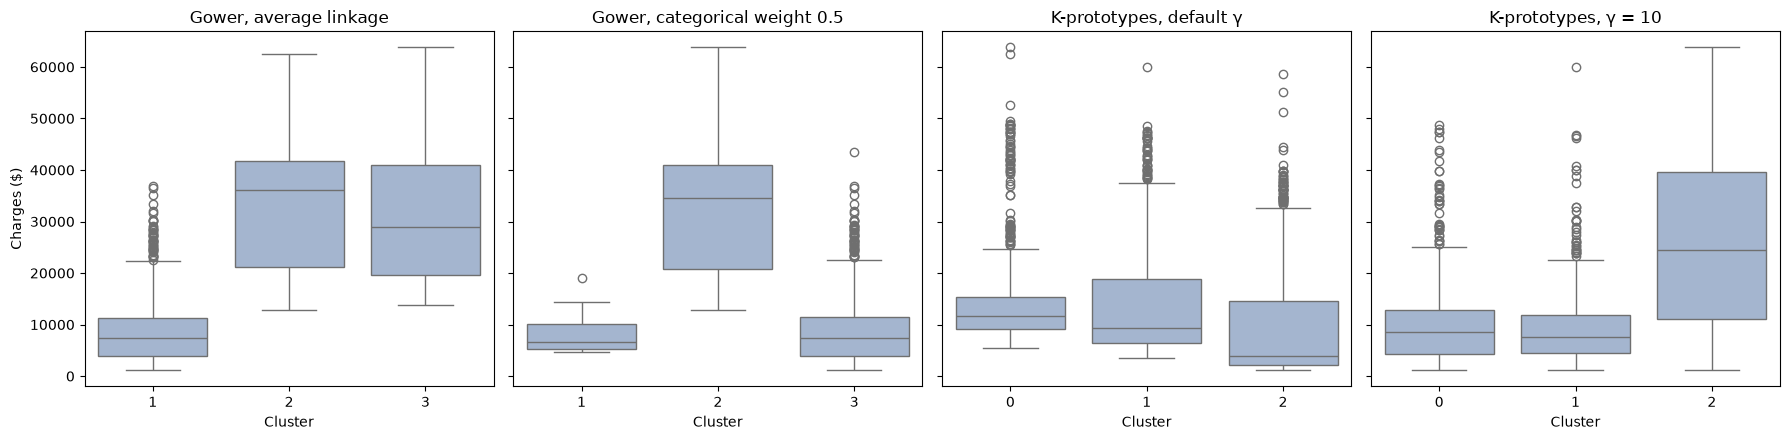

In [ ]:
# I used Gen AI to assist with the summary tables and boxplots.
solutions = [("avg3", "Gower, average linkage"),
             ("half3", "Gower, categorical weight 0.5"),
             ("kp_default", "K-prototypes, default γ"),
             ("kp_10", "K-prototypes, γ = 10")]

ins["is_smoker"] = ins["smoker"].eq("yes")      

for col, name in solutions:
    print(f"\n{name}")
    summary = ins.groupby(col).agg(n=("charges", "size"),
                                   mean_charges=("charges", "mean"),
                                   median_charges=("charges", "median"),
                                   smokers=("is_smoker", "sum"))
    display(summary.round(0))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, (col, name) in zip(axes, solutions):
    sns.boxplot(data=ins, x=col, y="charges", ax=ax, color="#9DB4D6")
    ax.set(title=name, xlabel="Cluster", ylabel="Charges ($)")
plt.tight_layout()
plt.show()

4.4 

- The clustering that separates people by charges best is Gower with Gamma = 0.5. We know this because one cluster's mean charge is significantly higher than the other two. This significant difference is also larger than that of the other clusters. However, this does not make it the right clustering automatically.

- This exercise has shown that data scientists have the power to decide which features determine clusters and how strongly those decisions are made. This has also shown that default gamma values aren't completely reliable and should be properly chosen before a full analysis. 